# SCM Model 06: Fu et al. Acne Trial Simulation

This notebook explores a simulation model based on Fu et al.'s acne treatment trial.

## Simulation Model Setup

Fu et al. used a total of 16 days of trial, split into 4 cycles consisting of two days of treatment and two days of no treatment. For simulation, we use 8 periods of two days length.

### Covariate Model
We use temperature $L_k$ as the covariate, generated using an AR(1) model fitted on the original temperature data:

$$\gamma_k \sim \mathcal{N}(a, b)$$
$$L_k = \phi L_{k-1} + \gamma_k$$

### Outcome Model
$$Y_k = \mu + \beta A_k + \ell L_k + \varepsilon$$

where $a, b, \phi$ are fitted on historical data.

### Treatment Effect Scenarios
- $\beta = 0$: Control group of non-responders
- $\beta = -0.179$: Responders (largest effect size in real trial data)

## Analysis Metrics
1. Best arm identification among everybody
2. Group of responders: times of receiving best treatment
3. Bias in estimating treatment effect through adaptive data collection

In [27]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import numpy
import torch
import seaborn
import pandas as pd
from adaptive_nof1 import *
from adaptive_nof1.policies import *
from adaptive_nof1.helpers import *
from adaptive_nof1.inference import *
from adaptive_nof1.metrics import *
from adaptive_nof1.models import *
from adaptive_nof1.basic_types import Observation
from matplotlib import pyplot as plt
from scipy import stats
import sklearn.linear_model

# Set random seed for reproducibility
numpy.random.seed(42)

## Trial Configuration

Following Fu et al.:
- 16 days total trial
- 4 cycles of (2 days treatment, 2 days no treatment)
- 8 periods of 2 days each

In [29]:
# Trial configuration based on Fu et al.
DAYS_PER_PERIOD = 2
NUMBER_OF_PERIODS = 8  # 4 cycles × 2 periods per cycle
TOTAL_DAYS = DAYS_PER_PERIOD * NUMBER_OF_PERIODS  # 16 days

# Simulation parameters
block_length = DAYS_PER_PERIOD
length = NUMBER_OF_PERIODS * block_length
number_of_actions = 2
number_of_patients = 100

print(f"Trial configuration:")
print(f"  Total days: {TOTAL_DAYS}")
print(f"  Number of periods: {NUMBER_OF_PERIODS}")
print(f"  Days per period: {DAYS_PER_PERIOD}")
print(f"  Total simulation length: {length} timesteps")

Trial configuration:
  Total days: 16
  Number of periods: 8
  Days per period: 2
  Total simulation length: 16 timesteps


## Fit AR(1) Model on Historical Temperature Data

In [30]:
# Load the acne data to fit AR(1) model on temperature
acne_df = pd.read_csv('../acne_data/scores-scaled-combined.csv')
acne_df["time"] = pd.to_datetime(acne_df["Timestamp (From Photo)(MMDD-YYYY-HHMMSS)"], format="%m%d-%Y-%H%M%S")
acne_df.sort_values(by=["Id", "time"], inplace=True)

# Extract temperature data
temperature_data = acne_df['Temperature (°F)'].dropna()

print(f"Temperature statistics:")
print(f"  Mean: {temperature_data.mean():.2f}°F")
print(f"  Std: {temperature_data.std():.2f}°F")
print(f"  Min: {temperature_data.min():.2f}°F")
print(f"  Max: {temperature_data.max():.2f}°F")
print(f"  N observations: {len(temperature_data)}")

Temperature statistics:
  Mean: 75.70°F
  Std: 2.17°F
  Min: 55.00°F
  Max: 79.00°F
  N observations: 255


In [31]:
def fit_ar1_model(data):
    """
    Fit an AR(1) model: L_k = phi * L_{k-1} + gamma_k
    where gamma_k ~ N(a, b)
    
    Returns:
        phi: AR(1) coefficient
        a: mean of innovation noise
        b: std of innovation noise
    """
    # Standardize the data
    data_centered = data - data.mean()
    
    # Fit AR(1) using OLS: L_k = phi * L_{k-1} + error
    L_k = data_centered.values[1:]
    L_k_minus_1 = data_centered.values[:-1]
    
    # Compute phi using OLS
    phi = numpy.sum(L_k * L_k_minus_1) / numpy.sum(L_k_minus_1 ** 2)
    
    # Compute residuals (innovations)
    residuals = L_k - phi * L_k_minus_1
    
    # Innovation parameters
    a = numpy.mean(residuals)  # Should be close to 0
    b = numpy.std(residuals)
    
    return phi, a, b, data.mean(), data.std()

# Fit AR(1) on all temperature data
phi, a, b, temp_mean, temp_std = fit_ar1_model(temperature_data)

print("AR(1) Model Parameters (fitted on temperature data):")
print(f"  φ (AR coefficient): {phi:.4f}")
print(f"  a (innovation mean): {a:.4f}")
print(f"  b (innovation std): {b:.4f}")
print(f"  Temperature mean: {temp_mean:.2f}°F")
print(f"  Temperature std: {temp_std:.2f}°F")

AR(1) Model Parameters (fitted on temperature data):
  φ (AR coefficient): 0.4484
  a (innovation mean): -0.0103
  b (innovation std): 1.9305
  Temperature mean: 75.70°F
  Temperature std: 2.17°F


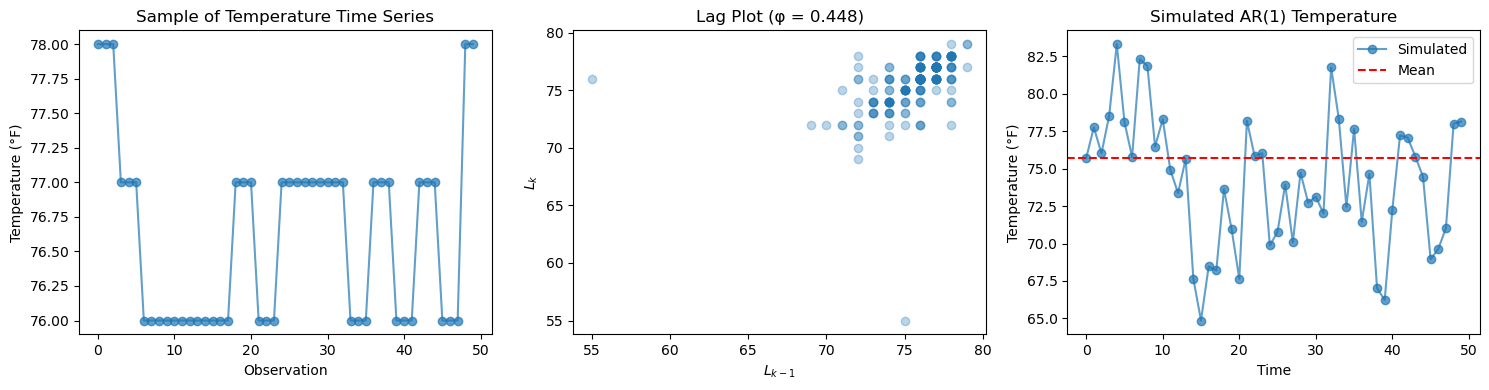

In [32]:
# Visualize the AR(1) fit
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Temperature time series
axes[0].plot(temperature_data.values[:50], 'o-', alpha=0.7)
axes[0].set_xlabel('Observation')
axes[0].set_ylabel('Temperature (°F)')
axes[0].set_title('Sample of Temperature Time Series')

# Plot 2: Lag plot (L_k vs L_{k-1})
axes[1].scatter(temperature_data.values[:-1], temperature_data.values[1:], alpha=0.3)
axes[1].set_xlabel('$L_{k-1}$')
axes[1].set_ylabel('$L_k$')
axes[1].set_title(f'Lag Plot (φ = {phi:.3f})')

# Plot 3: Simulated AR(1) vs observed
n_sim = 100
simulated_temp = numpy.zeros(n_sim)
simulated_temp[0] = 0  # Start at 0 (standardized)
for i in range(1, n_sim):
    gamma = numpy.random.normal(a, b)
    simulated_temp[i] = phi * simulated_temp[i-1] + gamma

# Convert back to original scale
simulated_temp_original = simulated_temp * temp_std + temp_mean

axes[2].plot(simulated_temp_original[:50], 'o-', alpha=0.7, label='Simulated')
axes[2].axhline(y=temp_mean, color='r', linestyle='--', label='Mean')
axes[2].set_xlabel('Time')
axes[2].set_ylabel('Temperature (°F)')
axes[2].set_title('Simulated AR(1) Temperature')
axes[2].legend()

plt.tight_layout()
plt.show()

## Define the Structural Causal Model

In [33]:
class FuTrialSCM(Model):
    """
    Structural Causal Model for Fu et al. acne trial simulation.
    
    Covariate model (AR(1) for temperature):
        γ_k ~ N(a, b)
        L_k = φ * L_{k-1} + γ_k
    
    Outcome model:
        Y_k = μ + β * A_k + ℓ * L_k + ε
    
    Parameters:
        beta: Treatment effect (-0.179 for responders, 0 for non-responders)
        mu: Baseline outcome level
        ell: Effect of temperature covariate on outcome
        phi: AR(1) coefficient for temperature
        a: Mean of AR(1) innovations
        b: Std of AR(1) innovations
    """
    
    def __init__(self, patient_id, beta, mu=0.5, ell=0.05, 
                 phi=0.3, a=0.0, b=1.0, outcome_variance=0.1,
                 name="FuTrialSCM"):
        self.patient_id = patient_id
        self.rng = numpy.random.default_rng(patient_id)
        
        # Model parameters
        self.beta = beta  # Treatment effect
        self.mu = mu  # Baseline
        self.ell = ell  # Temperature effect
        self.phi = phi  # AR(1) coefficient
        self.a = a  # Innovation mean
        self.b = b  # Innovation std
        self.outcome_variance = outcome_variance
        self.name = name
        
    def generate_context(self, history):
        """Generate temperature covariate using AR(1) model."""
        if len(history.observations) == 0:
            # Initialize with random draw from stationary distribution
            L = self.rng.normal(0, self.b / numpy.sqrt(1 - self.phi**2))
            return {"L": L, "Y_k_minus_1": 0.0}
        
        last_obs = history.observations[-1]
        L_k_minus_1 = last_obs.context["L"]
        Y_k_minus_1 = last_obs.outcome["outcome"]
        
        # AR(1) update: L_k = phi * L_{k-1} + gamma_k
        gamma_k = self.rng.normal(self.a, self.b)
        L_k = self.phi * L_k_minus_1 + gamma_k
        
        return {"L": L_k, "Y_k_minus_1": Y_k_minus_1}
    
    @property
    def number_of_interventions(self):
        return 2
    
    @property
    def additional_config(self):
        return {
            "beta": self.beta,
            "mu": self.mu,
            "ell": self.ell,
            "is_responder": self.beta != 0,
        }
    
    def observe_outcome(self, action, context):
        """
        Generate outcome: Y_k = μ + β * A_k + ℓ * L_k + ε
        
        Note: A_k = 1 means treatment, A_k = 0 means control
        For responders with β < 0, treatment reduces outcome (beneficial for acne)
        """
        A_k = action["treatment"]
        L_k = context["L"]
        
        # Outcome model
        epsilon = self.rng.normal(0, numpy.sqrt(self.outcome_variance))
        Y_k = self.mu + self.beta * A_k + self.ell * L_k + epsilon
        
        return {"outcome": Y_k}
    
    def __str__(self):
        responder_str = "responder" if self.beta != 0 else "non_responder"
        return f"{self.name}_{responder_str}"

## Define Simulation Scenarios

In [34]:
# Treatment effect parameters from Fu et al.
BETA_NON_RESPONDER = 0.0  # No treatment effect
BETA_RESPONDER = 0.2 

# Create scenario generators
def create_non_responder_generator(phi, a, b):
    """Create a generator for non-responders (β = 0)."""
    def generator(patient_id):
        return FuTrialSCM(
            patient_id=patient_id,
            beta=BETA_NON_RESPONDER,
            phi=phi,
            a=a,
            b=b,
            name="FuTrial_NonResponder"
        )
    return generator

def create_responder_generator(phi, a, b):
    """Create a generator for responders (β = -0.179)."""
    def generator(patient_id):
        return FuTrialSCM(
            patient_id=patient_id,
            beta=BETA_RESPONDER,
            phi=phi,
            a=a,
            b=b,
            name="FuTrial_Responder"
        )
    return generator

# Create generators with fitted AR(1) parameters
non_responder_generator = create_non_responder_generator(phi, a, b)
responder_generator = create_responder_generator(phi, a, b)

scenarios = {
    'non_responder': {
        'generator': non_responder_generator,
        'beta': BETA_NON_RESPONDER,
        'description': f'Non-responders (β = {BETA_NON_RESPONDER})'
    },
    'responder': {
        'generator': responder_generator,
        'beta': BETA_RESPONDER,
        'description': f'Responders (β = {BETA_RESPONDER})'
    }
}

print("Simulation Scenarios:")
for name, scenario in scenarios.items():
    print(f"  {name}: {scenario['description']}")

Simulation Scenarios:
  non_responder: Non-responders (β = 0.0)
  responder: Responders (β = 0.2)


## Define Inference Models

In [35]:
# Prior specification for Bayesian inference
PRIOR_SPEC = {
    'cov_diag': 10.0,  # Prior variance (moderately informative)
    'alpha': 2.0,  # Prior on variance (shape)
    'beta': 2.0,  # Prior on variance (rate)
}

def create_inference_model(include_covariate=True):
    """Create Bayesian linear regression model for inference."""
    if include_covariate:
        # Treatment (2 coefficients) + covariate L
        mean = numpy.array([0.0, 0.0, 0.0])
        v = numpy.eye(3) * PRIOR_SPEC['cov_diag']
        covariate_names = ["L"]
        name = "With_Covariate"
    else:
        # Treatment only (2 coefficients)
        mean = numpy.array([0.0, 0.0])
        v = numpy.eye(2) * PRIOR_SPEC['cov_diag']
        covariate_names = []
        name = "Without_Covariate"
    
    return BayesianLinearRegressionModel(
        mean=mean,
        v=v,
        alpha=PRIOR_SPEC['alpha'],
        beta=PRIOR_SPEC['beta'],
        covariate_names=covariate_names,
        name=name
    )

inference_models = {
    'without_covariate': create_inference_model(include_covariate=False),
    'with_covariate': create_inference_model(include_covariate=True),
}

print("Inference Models:")
for key, model in inference_models.items():
    print(f"  {key}: {model.name}")
    print(f"    Prior mean: {model.mean}")
    print(f"    Prior variance diagonal: {numpy.diag(model.v)}")

Inference Models:
  without_covariate: Without_Covariate
    Prior mean: [0. 0.]
    Prior variance diagonal: [10. 10.]
  with_covariate: With_Covariate
    Prior mean: [0. 0. 0.]
    Prior variance diagonal: [10. 10. 10.]


## Define Policies

In [36]:
# Define policies to compare
policies = [
    # Fixed randomization (baseline)
    BlockPolicy(
        block_length=block_length,
        internal_policy=FixedPolicy(
            inference_model=create_inference_model(include_covariate=False),
            block_length=block_length,
            randomize=True,
        ),
    ),
    
    # Constant policies (always treat / never treat)
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(action=0),  # Never treat
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(action=1),  # Always treat
    ),
    
    # Thompson Sampling without covariate
    BlockPolicy(
        block_length=block_length,
        internal_policy=ThompsonSampling(
            inference_model=create_inference_model(include_covariate=False),
        ),
    ),
    
    # Thompson Sampling with covariate
    BlockPolicy(
        block_length=block_length,
        internal_policy=ThompsonSampling(
            inference_model=create_inference_model(include_covariate=True),
        ),
    ),
]

policy_names = [
    "Fixed Randomization",
    "Never Treat",
    "Always Treat",
    "Thompson Sampling (no cov)",
    "Thompson Sampling (with cov)",
]

print("Policies to compare:")
for i, name in enumerate(policy_names):
    print(f"  {i+1}. {name}")

Policies to compare:
  1. Fixed Randomization
  2. Never Treat
  3. Always Treat
  4. Thompson Sampling (no cov)
  5. Thompson Sampling (with cov)


## Run Simulation

In [37]:
# Generate configuration cross product
study_designs = {
    "n_patients": [number_of_patients],
    "policy": policies,
    "model_from_patient_id": [
        scenario['generator'] for scenario in scenarios.values()
    ],
}

configurations = generate_configuration_cross_product(study_designs)
print(f"Total configurations to run: {len(configurations)}")

Total configurations to run: 10


In [38]:
ENABLE_SIMULATION = True

if ENABLE_SIMULATION:
    print("Running Fu et al. Trial Simulation...")
    calculated_series, config_to_simulation_data = simulate_configurations(
        configurations, length
    )
    
    # Save simulation results
    write_to_disk(
        "data/fu_trial_simulation.json",
        [calculated_series, config_to_simulation_data],
    )
    print("Simulation complete. Results saved.")
else:
    print("Loading simulation from disk...")
    calculated_series, config_to_simulation_data = load_from_disk(
        "data/fu_trial_simulation.json",
    )

Running Fu et al. Trial Simulation...


  0%|          | 0/16 [00:00<?, ?it/s]


AttributeError: 'History' object has no attribute 'outcomes'

## Analysis: Best Arm Identification

For analyzing results, we fit the Bayesian model and compare the posterior mean of β.

In [ ]:
# Define metrics
metrics = [
    CumulativeRegret(),
]

# Create policy mapping for cleaner labels
policy_mapping = {
    str(p): name for p, name in zip(policies, policy_names)
}

# Score the data
df = SeriesOfSimulationsData.score_data(
    [s["result"] for s in calculated_series],
    metrics,
    {"policy": lambda x: policy_mapping.get(x, x)},
)

print("Scoring complete.")
df.head()

Scoring complete.


,t,score,simulation,patient_id,model,policy,pooled,metric
0,0,-0.471802,SimulationData,0,FuTrial_NonResponder_non_responder,Fixed Randomization,False,Cumulative Regret (outcome)
1,1,-1.072365,SimulationData,0,FuTrial_NonResponder_non_responder,Fixed Randomization,False,Cumulative Regret (outcome)
2,2,-1.664709,SimulationData,0,FuTrial_NonResponder_non_responder,Fixed Randomization,False,Cumulative Regret (outcome)
3,3,-2.579691,SimulationData,0,FuTrial_NonResponder_non_responder,Fixed Randomization,False,Cumulative Regret (outcome)
4,4,-2.662870,SimulationData,0,FuTrial_NonResponder_non_responder,Fixed Randomization,False,Cumulative Regret (outcome)


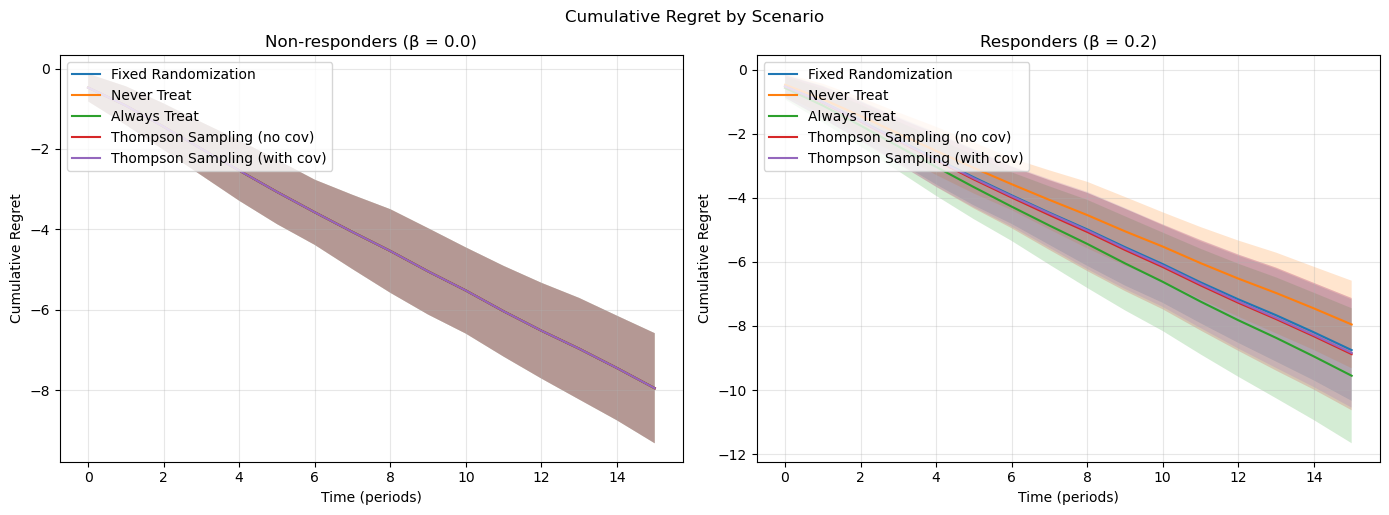

In [ ]:
# Plot cumulative regret
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (scenario_name, scenario) in enumerate(scenarios.items()):
    ax = axes[idx]
    
    # Filter data for this scenario
    scenario_df = df[df['model'].str.contains(scenario_name, case=False)]
    
    if len(scenario_df) > 0:
        for policy_name in policy_names:
            policy_df = scenario_df[scenario_df['policy'] == policy_name]
            if len(policy_df) > 0:
                # Group by time and calculate mean/std
                grouped = policy_df.groupby('t')['score'].agg(['mean', 'std'])
                ax.plot(grouped.index, grouped['mean'], label=policy_name)
                ax.fill_between(
                    grouped.index,
                    grouped['mean'] - grouped['std'],
                    grouped['mean'] + grouped['std'],
                    alpha=0.2
                )
    
    ax.set_xlabel('Time (periods)')
    ax.set_ylabel('Cumulative Regret')
    ax.set_title(f'{scenario["description"]}')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Cumulative Regret by Scenario', y=1.02)
plt.show()

## Analysis: Best Arm Identification Accuracy

BEST ARM IDENTIFICATION

Accuracy (Responders only):
(Using covariate model for inference on adaptively collected data)

  Fixed Randomization: 89.0%
  Thompson Sampling (with cov): 87.0%
  Thompson Sampling (no cov): 78.0%
  Always Treat: 0.0%
  Never Treat: 0.0%

BIAS IN TREATMENT EFFECT ESTIMATION

Responders (True β = 0.2):
                              β̂ Mean  β̂ Std    Bias     MAE
policy_name                                                  
Always Treat                   0.0000  0.0000 -0.2000  0.2000
Fixed Randomization            0.1590  0.1338 -0.0410  0.1093
Never Treat                    0.0000  0.0000 -0.2000  0.2000
Thompson Sampling (no cov)     0.1753  0.1575 -0.0247  0.1284
Thompson Sampling (with cov)   0.1769  0.1638 -0.0231  0.1334

Non-Responders (True β = 0.0):
                              β̂ Mean  β̂ Std    Bias     MAE
policy_name                                                  
Always Treat                   0.0000  0.0000  0.0000  0.0000
Fixed Randomizatio

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_75657/2645871096.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_75657/2645871096.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


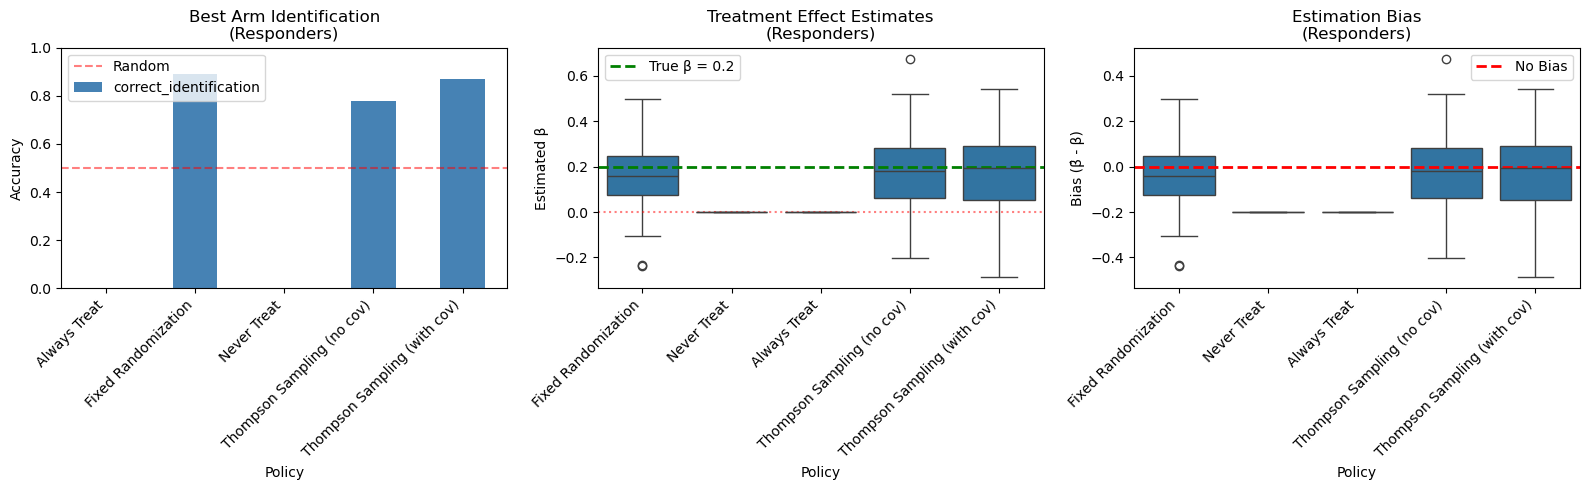

In [44]:
def compute_best_arm_identification(simulation_results):
    """
    Compute best arm identification metrics and estimation bias.
    
    Always uses the covariate model (with L) for inference, regardless of which
    policy was used for data collection. This allows us to assess how adaptive
    data collection affects inference quality.
    
    Model: Y_k = intercept + β * A_k + ℓ * L_k + ε
    
    For responders: best arm is treatment (action=1) since β > 0 increases outcome
    For non-responders: both arms are equivalent (β = 0)
    """
    results = []
    
    for sim in simulation_results:
        config = sim['configuration']
        result = sim['result']
        
        model_str = str(config.get('model', ''))
        is_responder = 'responder' in model_str.lower() and 'non' not in model_str.lower()
        true_beta = BETA_RESPONDER if is_responder else BETA_NON_RESPONDER
        
        for patient_data in result.simulations:
            # Prepare the data for Bayesian linear regression
            X_list = []
            y_list = []
            
            for obs in patient_data.history.observations:
                action = obs.treatment['treatment']
                L_k = obs.context['L']
                outcome = obs.outcome['outcome']
                
                # Design matrix: [treatment_indicator (A_k), covariate_L]
                # A_k = 1 for treatment, 0 for control
                X_list.append([action, L_k])
                y_list.append(outcome)
            
            if len(X_list) > 0:
                X = numpy.array(X_list)
                y = numpy.array(y_list)
                
                # Fit Bayesian Ridge regression (approximates Bayesian linear regression)
                bayesian_model = sklearn.linear_model.BayesianRidge(
                    alpha_1=PRIOR_SPEC['alpha'],
                    alpha_2=PRIOR_SPEC['beta'],
                    lambda_1=PRIOR_SPEC['alpha'],
                    lambda_2=PRIOR_SPEC['beta'],
                    compute_score=True
                )
                bayesian_model.fit(X, y)
                
                # Get posterior means: coef_[0] = β (treatment effect), coef_[1] = ℓ (covariate effect)
                estimated_beta = bayesian_model.coef_[0]
                estimated_ell = bayesian_model.coef_[1]
                intercept = bayesian_model.intercept_
                
                # Best arm identification: treatment is best if β > 0
                identified_best_arm = 1 if estimated_beta > 0 else 0
                
                # True best arm for responders is 1 (treatment) since β > 0
                true_best_arm = 1 if is_responder else 0  # For non-responders, either arm is fine
                
                # Bias computation
                bias = estimated_beta - true_beta
                
                results.append({
                    'policy': str(config.get('policy', '')),
                    'is_responder': is_responder,
                    'identified_best_arm': identified_best_arm,
                    'true_best_arm': true_best_arm,
                    'correct_identification': identified_best_arm == true_best_arm if is_responder else None,
                    'true_beta': true_beta,
                    'estimated_beta': estimated_beta,
                    'bias': bias,
                    'absolute_error': abs(bias),
                    'covariate_effect': estimated_ell,
                    'intercept': intercept,
                })
    
    return pd.DataFrame(results)

# Compute best arm identification using covariate model on all data
bai_df = compute_best_arm_identification(calculated_series)

if len(bai_df) > 0:
    # Map policy names
    bai_df['policy_name'] = bai_df['policy'].map(lambda x: policy_mapping.get(x, x))
    
    # === BEST ARM IDENTIFICATION ===
    print("=" * 80)
    print("BEST ARM IDENTIFICATION")
    print("=" * 80)
    
    # Compute accuracy for responders only
    responder_bai = bai_df[bai_df['is_responder'] == True]
    if len(responder_bai) > 0:
        accuracy_by_policy = responder_bai.groupby('policy_name')['correct_identification'].mean()
        print("\nAccuracy (Responders only):")
        print("(Using covariate model for inference on adaptively collected data)\n")
        for policy, acc in accuracy_by_policy.sort_values(ascending=False).items():
            print(f"  {policy}: {acc:.1%}")
    
    # === BIAS IN ESTIMATION ===
    print("\n" + "=" * 80)
    print("BIAS IN TREATMENT EFFECT ESTIMATION")
    print("=" * 80)
    
    for is_resp, group_name in [(True, "Responders"), (False, "Non-Responders")]:
        subset = bai_df[bai_df['is_responder'] == is_resp]
        if len(subset) > 0:
            true_val = BETA_RESPONDER if is_resp else BETA_NON_RESPONDER
            print(f"\n{group_name} (True β = {true_val}):")
            
            bias_stats = subset.groupby('policy_name').agg({
                'estimated_beta': ['mean', 'std'],
                'bias': 'mean',
                'absolute_error': 'mean'
            }).round(4)
            bias_stats.columns = ['β̂ Mean', 'β̂ Std', 'Bias', 'MAE']
            print(bias_stats.to_string())
    
    # === VISUALIZATION ===
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # Plot 1: Best Arm Identification Accuracy (Responders)
    ax = axes[0]
    if len(responder_bai) > 0:
        accuracy_by_policy.plot(kind='bar', ax=ax, color='steelblue')
        ax.set_xlabel('Policy')
        ax.set_ylabel('Accuracy')
        ax.set_title('Best Arm Identification\n(Responders)')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        ax.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Random')
        ax.set_ylim(0, 1)
        ax.legend()
    
    # Plot 2: Estimated β distribution (Responders)
    ax = axes[1]
    if len(responder_bai) > 0:
        seaborn.boxplot(data=responder_bai, x='policy_name', y='estimated_beta', ax=ax)
        ax.axhline(y=BETA_RESPONDER, color='g', linestyle='--', linewidth=2, label=f'True β = {BETA_RESPONDER}')
        ax.axhline(y=0, color='r', linestyle=':', alpha=0.5)
        ax.set_xlabel('Policy')
        ax.set_ylabel('Estimated β')
        ax.set_title('Treatment Effect Estimates\n(Responders)')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        ax.legend()
    
    # Plot 3: Bias distribution (Responders)
    ax = axes[2]
    if len(responder_bai) > 0:
        seaborn.boxplot(data=responder_bai, x='policy_name', y='bias', ax=ax)
        ax.axhline(y=0, color='r', linestyle='--', linewidth=2, label='No Bias')
        ax.set_xlabel('Policy')
        ax.set_ylabel('Bias (β̂ - β)')
        ax.set_title('Estimation Bias\n(Responders)')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        ax.legend()
    
    plt.tight_layout()
    plt.show()

else:
    print("No best arm identification data available.")

## Analysis: Times of Receiving Best Treatment (Responders)

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_75657/1774218851.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_75657/1774218851.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


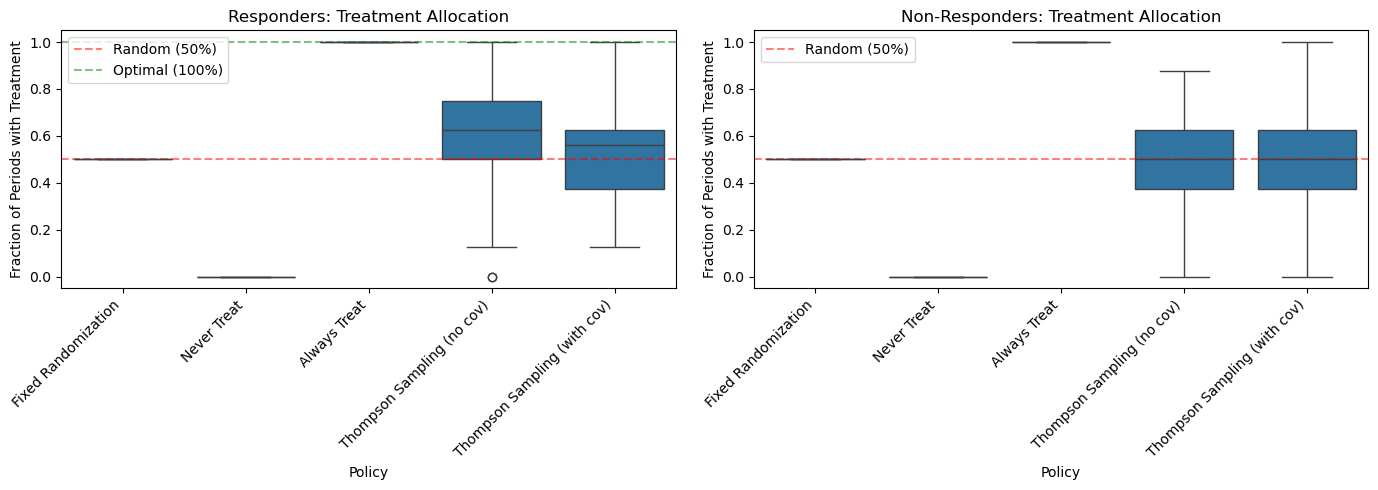


Treatment Allocation Summary (Mean ± Std):
                                              mean       std
is_responder policy_name                                    
False        Always Treat                  1.00000  0.000000
             Fixed Randomization           0.50000  0.000000
             Never Treat                   0.00000  0.000000
             Thompson Sampling (no cov)    0.46625  0.202459
             Thompson Sampling (with cov)  0.50250  0.203334
True         Always Treat                  1.00000  0.000000
             Fixed Randomization           0.50000  0.000000
             Never Treat                   0.00000  0.000000
             Thompson Sampling (no cov)    0.57875  0.220948
             Thompson Sampling (with cov)  0.55375  0.179659


In [45]:
def compute_treatment_allocation(simulation_results):
    """
    Compute how often each policy selected the best treatment.
    For responders, treatment (action=1) is best.
    """
    results = []
    
    for sim in simulation_results:
        config = sim['configuration']
        result = sim['result']
        
        model_str = str(config.get('model', ''))
        is_responder = 'responder' in model_str.lower() and 'non' not in model_str.lower()
        
        for patient_data in result.simulations:
            total_treatments = 0
            best_treatment_count = 0
            
            for obs in patient_data.history.observations:
                action = obs.treatment.get('treatment', 0)
                total_treatments += 1
                if action == 1:  # Treatment is best for responders
                    best_treatment_count += 1
            
            if total_treatments > 0:
                results.append({
                    'policy': str(config.get('policy', '')),
                    'is_responder': is_responder,
                    'total_periods': total_treatments,
                    'best_treatment_count': best_treatment_count,
                    'best_treatment_fraction': best_treatment_count / total_treatments,
                })
    
    return pd.DataFrame(results)

# Compute treatment allocation
allocation_df = compute_treatment_allocation(calculated_series)

if len(allocation_df) > 0:
    # Map policy names
    allocation_df['policy_name'] = allocation_df['policy'].map(lambda x: policy_mapping.get(x, x))
    
    # Plot treatment allocation for responders
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    for idx, (is_resp, title) in enumerate([(True, 'Responders'), (False, 'Non-Responders')]):
        ax = axes[idx]
        subset = allocation_df[allocation_df['is_responder'] == is_resp]
        
        if len(subset) > 0:
            seaborn.boxplot(
                data=subset, 
                x='policy_name', 
                y='best_treatment_fraction',
                ax=ax
            )
            ax.set_xlabel('Policy')
            ax.set_ylabel('Fraction of Periods with Treatment')
            ax.set_title(f'{title}: Treatment Allocation')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
            ax.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Random (50%)')
            if is_resp:
                ax.axhline(y=1.0, color='g', linestyle='--', alpha=0.5, label='Optimal (100%)')
            ax.legend()
    
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    print("\nTreatment Allocation Summary (Mean ± Std):")
    summary = allocation_df.groupby(['is_responder', 'policy_name'])['best_treatment_fraction'].agg(['mean', 'std'])
    print(summary)
else:
    print("No treatment allocation data available.")

## Summary and Conclusions

In [46]:
# Create summary table
print("="*80)
print("SIMULATION SUMMARY")
print("="*80)
print(f"\nTrial Configuration (following Fu et al.):")
print(f"  - Total days: {TOTAL_DAYS}")
print(f"  - Periods: {NUMBER_OF_PERIODS} (each {DAYS_PER_PERIOD} days)")
print(f"  - Number of patients: {number_of_patients}")

print(f"\nAR(1) Model Parameters (fitted on temperature data):")
print(f"  - φ: {phi:.4f}")
print(f"  - Innovation mean (a): {a:.4f}")
print(f"  - Innovation std (b): {b:.4f}")

print(f"\nTreatment Effect Scenarios:")
print(f"  - Non-responders: β = {BETA_NON_RESPONDER}")
print(f"  - Responders: β = {BETA_RESPONDER}")

print(f"\nPolicies Compared:")
for name in policy_names:
    print(f"  - {name}")

print("\n" + "="*80)
print("KEY FINDINGS")
print("="*80)

if len(allocation_df) > 0:
    print("\n1. Treatment Allocation (Responders - fraction receiving treatment):")
    responder_alloc = allocation_df[allocation_df['is_responder'] == True].groupby('policy_name')['best_treatment_fraction'].mean()
    for policy, frac in responder_alloc.items():
        print(f"   {policy}: {frac:.2%}")

if len(bias_df) > 0:
    print("\n2. Treatment Effect Estimation Bias (Responders):")
    responder_bias = bias_df[bias_df['is_responder'] == True].groupby('policy_name')['bias'].mean()
    for policy, bias_val in responder_bias.items():
        print(f"   {policy}: {bias_val:+.4f}")

SIMULATION SUMMARY

Trial Configuration (following Fu et al.):
  - Total days: 16
  - Periods: 8 (each 2 days)
  - Number of patients: 100

AR(1) Model Parameters (fitted on temperature data):
  - φ: 0.4484
  - Innovation mean (a): -0.0103
  - Innovation std (b): 1.9305

Treatment Effect Scenarios:
  - Non-responders: β = 0.0
  - Responders: β = 0.2

Policies Compared:
  - Fixed Randomization
  - Never Treat
  - Always Treat
  - Thompson Sampling (no cov)
  - Thompson Sampling (with cov)

KEY FINDINGS

1. Treatment Allocation (Responders - fraction receiving treatment):
   Always Treat: 100.00%
   Fixed Randomization: 50.00%
   Never Treat: 0.00%
   Thompson Sampling (no cov): 57.88%
   Thompson Sampling (with cov): 55.38%


In [48]:
# Final visualization: Combined metrics
if len(bias_df) > 0 and len(allocation_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # 1. Cumulative regret at final time
    final_regret = df[df['t'] == df['t'].max()].groupby('policy')['score'].mean()
    final_regret_mapped = {policy_mapping.get(k, k): v for k, v in final_regret.items()}
    
    ax = axes[0]
    pd.Series(final_regret_mapped).plot(kind='bar', ax=ax, color='steelblue')
    ax.set_xlabel('Policy')
    ax.set_ylabel('Cumulative Regret')
    ax.set_title('Final Cumulative Regret')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    # 2. Treatment allocation for responders
    ax = axes[1]
    responder_alloc = allocation_df[allocation_df['is_responder'] == True].groupby('policy_name')['best_treatment_fraction'].mean()
    responder_alloc.plot(kind='bar', ax=ax, color='green')
    ax.set_xlabel('Policy')
    ax.set_ylabel('Fraction')
    ax.set_title('Treatment Allocation (Responders)')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.axhline(y=0.5, color='r', linestyle='--', alpha=0.5)
    
    # 3. Absolute bias for responders
    ax = axes[2]
    responder_mae = bias_df[bias_df['is_responder'] == True].groupby('policy_name')['absolute_error'].mean()
    responder_mae.plot(kind='bar', ax=ax, color='orange')
    ax.set_xlabel('Policy')
    ax.set_ylabel('Mean Absolute Error')
    ax.set_title('Treatment Effect Estimation Error')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.suptitle('Comparison of Policies Across Key Metrics', y=1.02)
    plt.show()